# 06 — Modelo 2: Random Forest

**Elaborado por:** David Rodriguez

## Objetivo

Entrenar un **Random Forest** con las mismas 11 variables y los mismos mapas que la regresión
logística del cuadernillo 05, y medirlo en validación (2025). La pregunta es si un modelo que
capta relaciones más complejas predice mejor que el modelo lineal.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

from src.config import PROCESSED_DIR, TABLES_DIR, load_config
from src.evaluation import accuracy_interval, evaluate, temporal_split
from src.plotting import set_style, save_fig

set_style()
config = load_config()
FEATURES, TARGET, SEED = config["features"], config["target"], config["seed"]

dataset = pd.read_csv(PROCESSED_DIR / "dataset.csv")
train, val, test = temporal_split(dataset, config["split"])
train_fit = train[train["min_maps_played"] >= config["min_train_history"]]
X_train, y_train = train_fit[FEATURES], train_fit[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
print(f"Entrenamiento: {len(train_fit)} mapas | Validación: {len(val)} mapas | Variables: {len(FEATURES)}")

Entrenamiento: 5106 mapas | Validación: 1272 mapas | Variables: 11


## 1. Qué es un Random Forest y por qué se prueba

Un **árbol de decisión** hace preguntas en cadena sobre las variables ("¿la diferencia de
winrate es mayor que 0.1?", "¿la diferencia de rondas es mayor que 1.5?") hasta llegar a una
hoja, que da la predicción. Un solo árbol tiende a memorizar los datos con los que se entrenó.

Un **Random Forest** ("bosque aleatorio") entrena cientos de árboles, cada uno con una muestra
distinta de los mapas y de las variables, y **promedia** sus respuestas. Los errores de un
árbol se compensan con los de otro.

**Por qué se prueba:** cada árbol puede captar **no linealidades e interacciones** que la
regresión logística no ve. Es robusto a valores atípicos y a variables en escalas distintas
(no necesita estandarizar), y funciona razonablemente bien sin ajustar casi nada.

**Configuración:**

- `n_estimators=300`: 300 árboles.
- `min_samples_leaf=20`: cada hoja debe tener al menos 20 mapas. Con una señal tan débil,
  dejar que los árboles crezcan hasta hojas de un solo mapa haría que memorizaran ruido;
  exigir 20 mapas por hoja obliga a que cada probabilidad salga de un grupo con respaldo.
- Los faltantes se rellenan igual que en la logística (mediana + indicador de faltante).

**Límite:** es menos interpretable que la logística y sus probabilidades tienden a quedarse
cerca del centro.

In [2]:
model = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True),
    RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=SEED, n_jobs=-1),
).fit(X_train, y_train)

metrics = evaluate(y_val, model.predict_proba(X_val)[:, 1])
low, high = accuracy_interval(metrics["accuracy"], len(val))
print(f"Exactitud en validación: {metrics['accuracy']:.3f}  (IC 95 %: {low:.3f} – {high:.3f})")
pd.DataFrame({"Random Forest": metrics}).T.to_csv(TABLES_DIR / "06_resultados_random_forest.csv")

pd.DataFrame({"entrenamiento": evaluate(y_train, model.predict_proba(X_train)[:, 1]),
              "validación": metrics}).round(4)

Exactitud en validación: 0.564  (IC 95 %: 0.536 – 0.591)


,entrenamiento,validación
accuracy,0.7499,0.5637
roc_auc,0.8278,0.5810
log_loss,0.5908,0.6884


La columna de **entrenamiento** siempre sale mejor que la de **validación**: el modelo ya vio
esos mapas. Esa diferencia se llama *sobreajuste* y es la razón por la que un modelo nunca se
evalúa con los datos con los que aprendió. El número que vale es el de validación.

## 2. ¿Qué variables usa el bosque?

Un Random Forest calcula la **importancia** de cada variable: cuánto ayudó, sumando todos los
árboles, a separar victorias de derrotas cada vez que se usó en una pregunta.

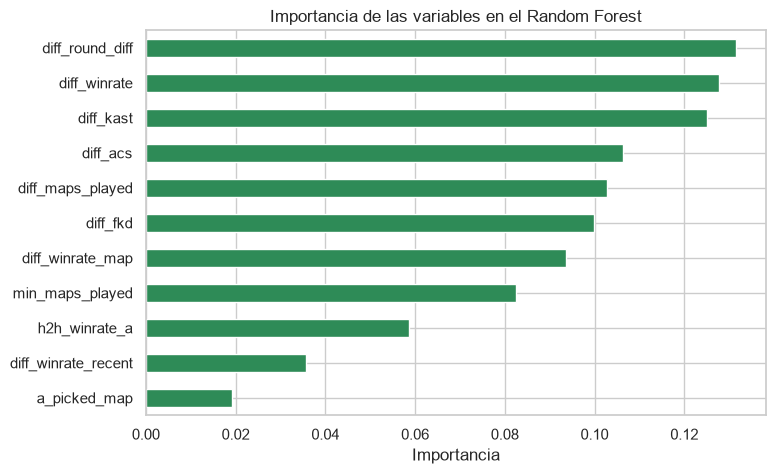

In [3]:
importances = pd.Series(model[-1].feature_importances_, index=model[:-1].get_feature_names_out())
importances = importances[~importances.index.str.startswith("missingindicator")].sort_values()
ax = importances.plot.barh(color="seagreen", figsize=(8, 5))
ax.set(title="Importancia de las variables en el Random Forest", xlabel="Importancia")
save_fig("06_importancia_random_forest")
plt.show()

**Por qué este gráfico:** a un bosque de 300 árboles no se le pueden leer coeficientes como a la logística. La importancia de variables es la forma estándar de ver en qué se apoya, y las barras horizontales ordenadas dejan el ranking a la vista.

**Cómo se lee:** cada barra es una variable; su largo es la parte del "trabajo" de separar victorias de derrotas que hizo esa variable (las importancias de todas las columnas suman 1). Una barra más larga significa que el bosque la usó más y con más provecho. No indica dirección (a favor o en contra), solo cuánto se usa.

**Qué muestra:** el bosque reparte su atención entre varias variables de rendimiento (margen de rondas, winrate, KAST, ACS) y la experiencia; ninguna domina. `a_picked_map` casi no se usa: solo toma tres valores y su señal es mínima. Coincide con lo visto en el cuadernillo 04: la señal está repartida entre variables que cuentan historias parecidas.

## Conclusiones

1. **Resultado del Random Forest en validación (2025):** exactitud 0.564
   (IC 95 %: 0.536–0.591), ROC-AUC 0.581 y log loss 0.688.
2. **No mejora a la regresión logística** (0.572, 0.599 y 0.688). Captar relaciones más
   complejas no ayudó: con tan poca señal, lo que hay para aprender es casi lineal.
3. **Sobreajuste visible:** el bosque se ve mucho mejor en entrenamiento que en validación.
   Por eso el modelo se juzga solo con datos que no vio.
4. **Variables:** usa sobre todo las de rendimiento general y la experiencia, de forma repartida.

**Siguiente paso (cuadernillo 07):** el tercer modelo, Gradient Boosting.